In [1]:
# Generating adjacency matrix (A)
# Calculate GIP kernel similarities for miRNAs and diseases
# Calculate the final integrated similarity of mirnas (SM) and diseases (SD) 
# which are used af features in the association prediction model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.metrics import accuracy_score
import scipy as sp

from sklearn.model_selection import train_test_split
from pathlib import Path

In [2]:
# reading data sets associations, mirna names and disease names respectively
m_d_associations = pd.read_csv('datasets/1.miRNA_disease_association/miRNA-disease-association-data.csv', header=0, names=["MiRNA","Disease"])
disease_names = pd.read_csv('datasets/1.miRNA_disease_association/disease name.csv', header=None)
mirna_names = pd.read_csv('datasets/1.miRNA_disease_association/miRNA name.csv', header=None)

In [3]:
# directories
OUT_DIR = Path("leakage_free_70_30") # root output directory
SPLIT_DIR = OUT_DIR / "data_split"
GIP_DIR = OUT_DIR / "GIP_similarities"
INTEGRATED_DIR = OUT_DIR / "integrated_similarities"

for directory in [SPLIT_DIR, GIP_DIR, INTEGRATED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

In [4]:
# LEAKAGE-FREE 70/30 ASSOCIATION HOLDOUT

RANDOM_STATE = 42

train_positive_pairs, test_positive_pairs = train_test_split(m_d_associations, test_size=0.30, random_state=RANDOM_STATE, shuffle=True)

train_positive_pairs = train_positive_pairs.reset_index(drop=True)
test_positive_pairs = test_positive_pairs.reset_index(drop=True)

print("Total known associations:", len(m_d_associations))
print("Training positive associations:", len(train_positive_pairs))
print("Held-out positive associations:", len(test_positive_pairs))

train_positive_pairs.to_csv(SPLIT_DIR / "train_positive_pairs.csv", index=False)
test_positive_pairs.to_csv(SPLIT_DIR / "heldout_positive_pairs.csv", index=False)

Total known associations: 5430
Training positive associations: 3801
Held-out positive associations: 1629


In [5]:
# getting number of mirnas, diseases and associations
nm = len(mirna_names)
nd = len(disease_names)
associations = len(m_d_associations)

nm, nd, associations

(495, 383, 5430)

In [6]:
m_d_associations.head()

,MiRNA,Disease
0,1,1
1,2,1
2,3,1
3,4,2
4,5,2


In [7]:
# FS:the functional similarity between m(i) and m(j)
# FSP:Functional similarity weighting matrix
# SS:the semantic similarity between d(i) and d(j).
# SSP:semantic similarity weighting matrix

FS = pd.read_table('datasets/4.miRNA functional simialrity/functional similarity matrix.txt', header=None)
FSP = pd.read_table('datasets/4.miRNA functional simialrity/functional similarity weight matrix.txt', header=None)
SS1 = pd.read_table('datasets/2.disease semantic similarity 1/disease semantic similarity matrix 1.txt', header=None);
SS2 = pd.read_table('datasets/3.disease semantic similarity 2/disease semantic similarity matrix 2.txt', header=None);
SS = (SS1+SS2)/2
SSP = pd.read_table('datasets/2.disease semantic similarity 1/disease semantic similarity weighting matrix1.txt', header=None);

In [8]:
# Disease semantic similarity
SS

,0,1,2,3,4,5,6,7,8,9,...,373,374,375,376,377,378,379,380,381,382
0,1.00000,0.038240,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.059719,0.049938,0.0,0.000000,0.0,0.000000,0.00000
1,0.03824,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.084313,0.000000,0.000000,...,0.0,0.0,0.073187,0.097589,0.121246,0.0,0.000000,0.0,0.034299,0.00000
2,0.00000,0.000000,1.000000,0.015619,0.00000,0.152393,0.244850,0.000000,0.188205,0.164830,...,0.0,0.0,0.000000,0.066923,0.056765,0.0,0.000000,0.0,0.059536,0.00000
3,0.00000,0.000000,0.015619,1.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.164015,0.0,0.098012,0.00000
4,0.00000,0.000000,0.000000,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.188323,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.09223
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,1.0,0.000000,0.0,0.000000,0.00000
379,0.00000,0.000000,0.000000,0.164015,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.0,1.000000,0.0,0.119578,0.00000
380,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000,1.0,0.000000,0.00000
381,0.00000,0.034299,0.059536,0.098012,0.00000,0.090869,0.106929,0.000000,0.029568,0.026842,...,0.0,0.0,0.000000,0.028992,0.025345,0.0,0.119578,0.0,1.000000,0.00000


In [9]:
# appending elements for mirnas and diseases as an list
m = []
d = []

for i, j in m_d_associations.itertuples(index=False):
    m.append(i)
    d.append(j)

# numpy matrix of association data (will be used to amake a dgl graph)
assoc_mat = np.array([[m],[d]])

In [10]:
len(m), len(d), assoc_mat

(5430,
 5430,
 array([[[  1,   2,   3, ...,  14, 116, 148]],
 
        [[  1,   1,   1, ..., 383, 383, 383]]], shape=(2, 1, 5430)))

In [11]:
# setting row and column names
ds = []
mr = []

for i in range(1, nd+1):
    ds.append(i)
for j in range(1, nm+1):
    mr.append(j)
    
column_names = ds
row_names = mr

# Creating an adjacency matrix as a zero matrix
adj = pd.DataFrame(np.zeros((nm,nd)), index=row_names, columns=column_names)

In [12]:
# Displaying empty adjacency matrix
adj

,1,2,3,4,5,6,7,8,9,10,...,374,375,376,377,378,379,380,381,382,383
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
492,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
493,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
494,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
# # adj: adajency matrix for the disease-miRNA association network
# # adj(i,j)=1 means miRNA i is related to disease j

# for row, col in m_d_associations.itertuples(index=False):
#     for i in adj.index:
#         for j in adj.index:
#             if i == row and j == col:
#                 adj.loc[i][j] = 1

In [14]:
# BUILDINF TRAINING ADJACENCY MATRIX
#
# IMPORTANT: Only the 70% training positive associations are inserted.
# Held-out positive associations therefore remain 0.

for mirna, disease in train_positive_pairs.itertuples(index=False):
    adj.loc[mirna, disease] = 1

In [15]:
print("A_train shape:", adj.shape)
print("Associations present in A_train:", int(adj.to_numpy().sum()))

assert int(adj.to_numpy().sum()) == len(train_positive_pairs)

A_train shape: (495, 383)
Associations present in A_train: 3801


In [16]:
# verifying that all 1,629 test positives are masked
heldout_values = np.array([
    adj.loc[mirna, disease]
    for mirna, disease in test_positive_pairs.itertuples(index=False)
])

print("Held-out positives:", len(heldout_values))
print("Held-out entries equal to 0:", np.sum(heldout_values == 0))
print("Held-out entries equal to 1:", np.sum(heldout_values == 1))

assert np.all(heldout_values == 0), \
    "ERROR: Some held-out associations remain in A_train!"

Held-out positives: 1629
Held-out entries equal to 0: 1629
Held-out entries equal to 1: 0


In [17]:
# saving training adjacent matrix
np.savetxt(SPLIT_DIR / "adjacency_matrix_train_70.txt", adj, fmt="%1.0f")

In [18]:
# converting the adjacency matrix to a numpy array
adj = adj.to_numpy()
print(adj), adj.shape

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 1. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


(None, (495, 383))

# Calculating GIP kernel similarities

In [19]:
def GIP(adj=None):
    if isinstance(adj, pd.DataFrame):
        adj = adj.to_numpy()
    n = adj.shape[0]
    gama = n / (np.linalg.norm(adj, ord="fro")**2)
    k = np.zeros((n, n))
    D = np.matmul(adj, adj.T)
    for i in range(n):
        for j in range(i, n):
            k[i, j] = np.exp(-gama * (D[i, i] + D[j, j] - 2*D[i, j]))
    k = k + k.T - np.diag(np.diag(k))
    return k

In [20]:
kd = GIP(adj=adj.T) # For diseases GIP, disease as column
km = GIP(adj=adj) # For mRNA GIP, mRNA as rows

# saving
np.savetxt(GIP_DIR / "mirna_GIP_train.txt", km)
np.savetxt(GIP_DIR / "disease_GIP_train.txt", kd)

In [21]:
# mirna and disease GIP matrix shapes
kd.shape, km.shape

((383, 383), (495, 495))

In [22]:
# mirnas GIP similarity
print(km)
# np.savetxt("mirna_gip_similarity.txt", km, fmt='%1.3f')

[[1.         0.02289956 0.06490656 ... 0.08421781 0.07393435 0.07393435]
 [0.02289956 1.         0.09593159 ... 0.07393435 0.08421781 0.08421781]
 [0.06490656 0.09593159 1.         ... 0.27190872 0.23870716 0.23870716]
 ...
 [0.08421781 0.07393435 0.27190872 ... 1.         0.87789447 0.87789447]
 [0.07393435 0.08421781 0.23870716 ... 0.87789447 1.         0.7706987 ]
 [0.07393435 0.08421781 0.23870716 ... 0.87789447 0.7706987  1.        ]]


In [23]:
# diseases GIP similarity
print(kd)

[[1.         0.54630506 0.40378747 ... 0.81748239 0.40378747 0.54630506]
 [0.54630506 1.         0.40378747 ... 0.66827746 0.40378747 0.54630506]
 [0.40378747 0.40378747 1.         ... 0.49394026 0.29844922 0.60422128]
 ...
 [0.81748239 0.66827746 0.49394026 ... 1.         0.49394026 0.66827746]
 [0.40378747 0.40378747 0.29844922 ... 0.49394026 1.         0.40378747]
 [0.54630506 0.54630506 0.60422128 ... 0.66827746 0.40378747 1.        ]]


# Plotting FS, SS and Adjacency matrix

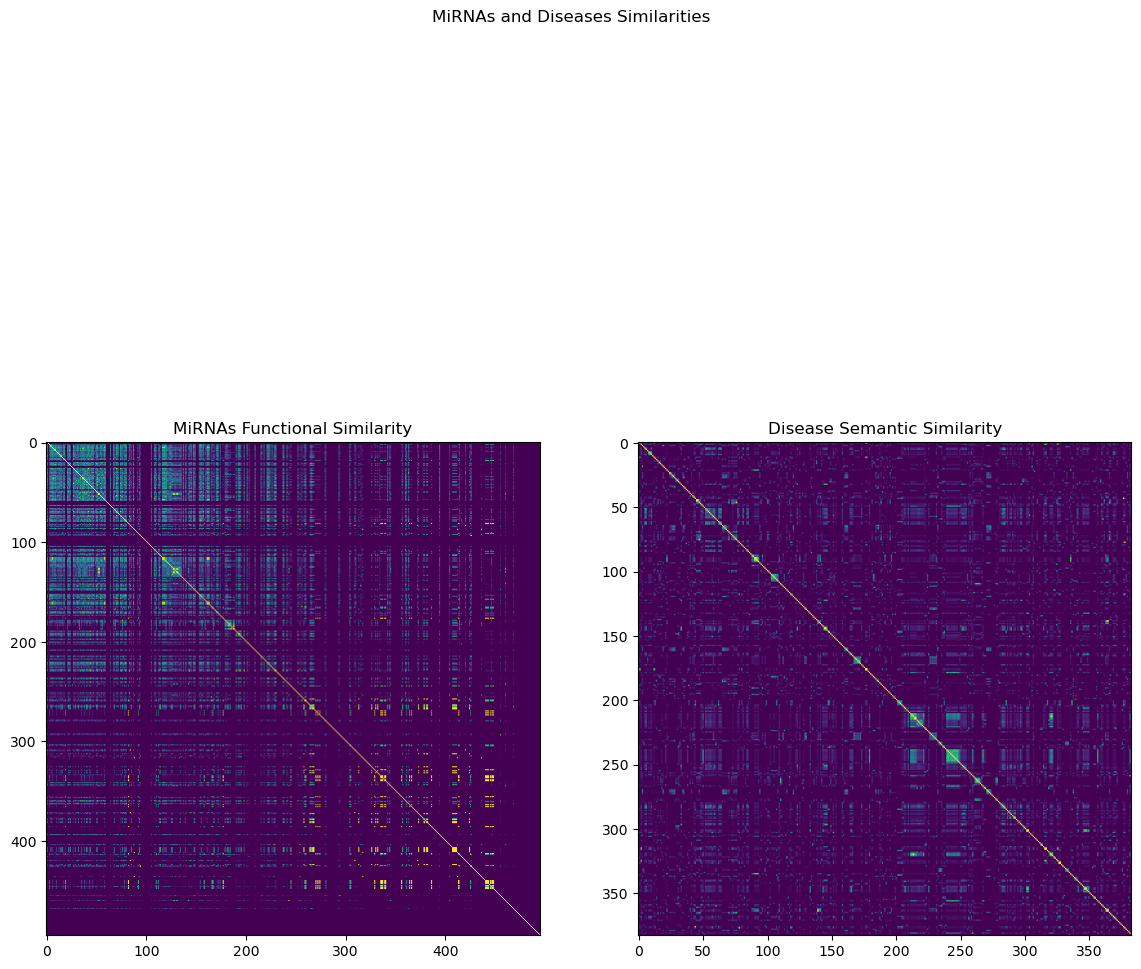

In [24]:
# mirna functional similarity and disease semantic similarity figures

fig, (fig1, fig2) = plt.subplots(1, 2, figsize=(14,14))
fig.suptitle('MiRNAs and Diseases Similarities')
fig1.title.set_text('MiRNAs Functional Similarity')
fig2.title.set_text('Disease Semantic Similarity')
fig1.imshow(FS)
fig2.imshow(SS)

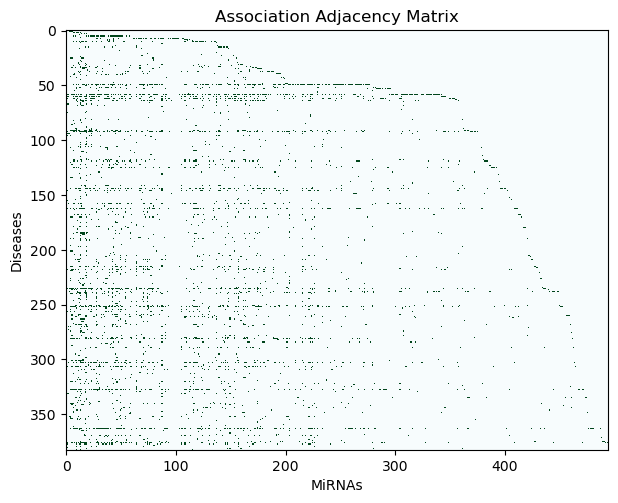

In [25]:
#Plot adjacency matrix in toned-down black and white
fig = plt.figure(figsize=(7, 10)) # in inches
plt.title('Association Adjacency Matrix')
plt.xlabel('MiRNAs')
plt.ylabel('Diseases')
plt.imshow(adj.T,
              cmap="BuGn",
              interpolation="none")

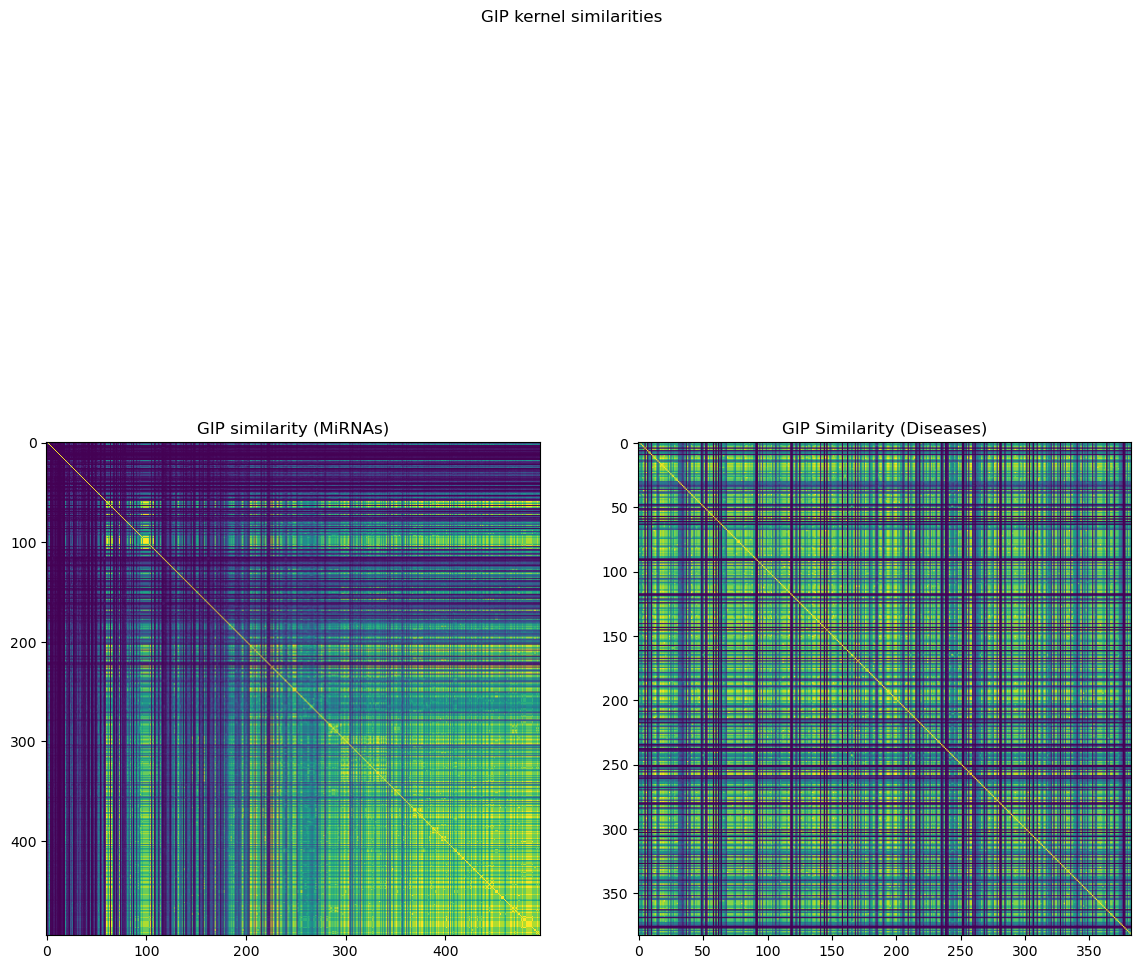

In [26]:
# plotting GIP similarities for mirnas and diseases
fig, (fig_1, fig_2) = plt.subplots(1, 2, figsize=(14,14))
fig.suptitle('GIP kernel similarities')
fig_1.title.set_text('GIP similarity (MiRNAs)')
fig_2.title.set_text('GIP Similarity (Diseases)')
fig_1.imshow(km)
fig_2.imshow(kd)

In [27]:
# mrna functional similarity shape and disease sematic similarity shape
FS.shape, SS.shape, km.shape, kd.shape

((495, 495), (383, 383), (495, 495), (383, 383))

# Integration of FS, SS with km and kd respectively

In [28]:
# function used to check for zeros in the arrays
def check_zeros(k):
    has_zeros = np.any((k==0))
    if has_zeros:
        return True
    return False

In [29]:
# interegrating gip kernel similarity with thr mirna and disease similarities
# array = mirna and disease similarities
# gip_array = kd or km
def integratedSimilarity(array=None, gip_array=None):
    if isinstance(array, pd.DataFrame):
        array = array.to_numpy()
    if isinstance(gip_array, pd.DataFrame):
        gip_array = gip_array.to_numpy()
    n = len(array)
    array_flattened = array.flatten()
    gip_array_flattened = gip_array.flatten()
    for i, e in np.ndenumerate(array_flattened):
        if array_flattened[i] == 0:
            array_flattened[i] = gip_array_flattened[i]
    intSim = array_flattened.reshape(n, n)
    return intSim

In [30]:
# integrated similarity for mirnas (MS) and diseases (DS)
SM = integratedSimilarity(FS, km)
SD = integratedSimilarity(SS, kd)
# np.savetxt("mirna_integrated_similarity.txt", SM)
# np.savetxt("disease_integrated_similarity.txt", SD)

np.savetxt(INTEGRATED_DIR / "mirna_integrated_similarity_train.txt", SM)
np.savetxt(INTEGRATED_DIR / "disease_integrated_similarity_train.txt", SD)


In [31]:
check_zeros(km), check_zeros(kd), check_zeros(SM), check_zeros(SD)

(False, False, False, False)

In [32]:
# previewing integrated similarity for mirna
print(SM)

[[1.         0.4768     0.06490656 ... 0.08421781 0.07393435 0.07393435]
 [0.4768     1.         0.09593159 ... 0.07393435 0.08421781 0.08421781]
 [0.06490656 0.09593159 1.         ... 0.27190872 0.23870716 0.23870716]
 ...
 [0.08421781 0.07393435 0.27190872 ... 1.         0.87789447 0.87789447]
 [0.07393435 0.08421781 0.23870716 ... 0.87789447 1.         0.7706987 ]
 [0.07393435 0.08421781 0.23870716 ... 0.87789447 0.7706987  1.        ]]


In [33]:
# previewing integrated similarity for mirna
print(SD)

[[1.         0.03824026 0.40378747 ... 0.81748239 0.40378747 0.54630506]
 [0.03824026 1.         0.40378747 ... 0.66827746 0.03429852 0.54630506]
 [0.40378747 0.40378747 1.         ... 0.49394026 0.05953641 0.60422128]
 ...
 [0.81748239 0.66827746 0.49394026 ... 1.         0.49394026 0.66827746]
 [0.40378747 0.03429852 0.05953641 ... 0.49394026 1.         0.40378747]
 [0.54630506 0.54630506 0.60422128 ... 0.66827746 0.40378747 1.        ]]
